In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision

from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import numpy as np

In [2]:
import torch
import torchvision
import torchvision.datasets as datasets
import torchvision.transforms as transforms
import torch.optim as optim
from torch.utils.data import random_split
    
import numpy as np 
import matplotlib.pyplot as plt 

# Downloading data 

Run the code block below to download all the data you need for task 1 and 2 (took me like 20 minutes for the CIFAR10 datasets, but the other ones were pretty quick)

To (un)comment multiple lines: CTRL + /

Please leave it uncommented after using, so we don't have to download all the data again when we rerun the notebook

In [3]:
# # Download the CIFAR datasets
# cifar10_train = datasets.CIFAR10(root = "./data", train = True, download = True)
# cifar10_test = datasets.CIFAR10(root = "./data", train = False, download = True)

# # Download Fashion-MNIST datasets
# fashion_train = datasets.FashionMNIST(root = "./data", train = True, download = True)
# fashion_test = datasets.FashionMNIST(root = "./data", train = False, download = True)

# # Download time datasets (Task 2)
# import os
# from urllib.request import urlretrieve
# import zipfile

# urls = ["https://surfdrive.surf.nl/public.php/dav/files/Nznt5c48Mzlb2HY/A1_data_75.zip", 
#         "https://surfdrive.surf.nl/public.php/dav/files/Nznt5c48Mzlb2HY/A1_data_150.zip"]

# target_folder = "./data"

# for url in urls:
#     file_name = os.path.basename(url)
#     full_path = os.path.join(target_folder, file_name)

#     # Create separate folder for each dataset 
#     dataset_name = os.path.splitext(file_name)[0]
#     extract_folder = os.path.join(target_folder, dataset_name)
#     os.makedirs(extract_folder, exist_ok = True)

#     # Download zip file
#     urlretrieve(url, full_path)

#     # Extract zip file
#     with zipfile.ZipFile(full_path, "r") as zip_ref:
#         zip_ref.extractall(extract_folder)

#     # Remove ZIP file
#     os.remove(full_path)

# Task 1

## Fashion MNIST

### Processing

**Loading data: train, validation, test**

In [4]:
transform = transforms.Compose([
    transforms.ToTensor() # Tbh I still don't know what tensors do 
])

# Load the data 
fashion_train_all = datasets.FashionMNIST(root = "./data", train = True, download = True, transform = transform)
fashion_test = datasets.FashionMNIST(root = "./data", train = False, download = True, transform = transform)

# Split 10% of training data for the validation set
train_size = int(0.9 * len(fashion_train_all))
validation_size = len(fashion_train_all) - train_size

fashion_train, fashion_validation = random_split(
    fashion_train_all,
    [train_size, validation_size],
    generator = torch.Generator().manual_seed(67) # (our group number)
)

**Visualise**

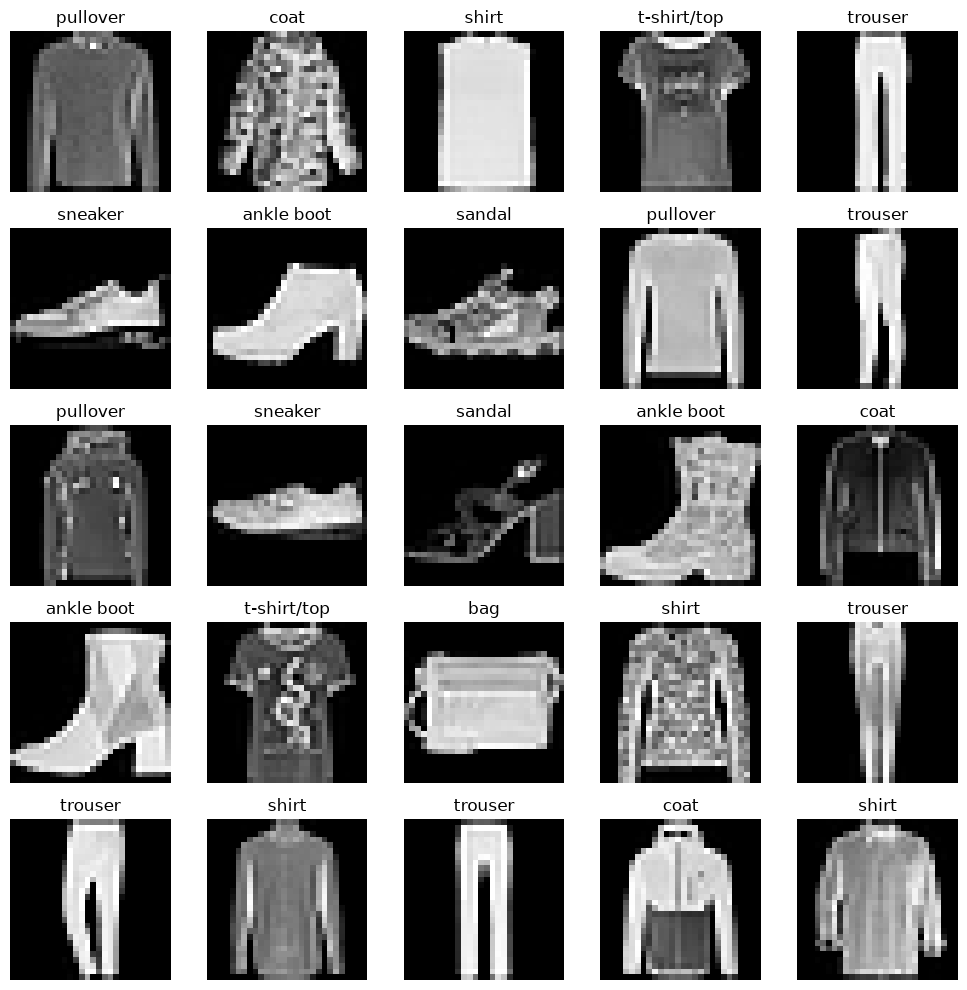

In [5]:
# Define class names
fashion_names = {
    0: "t-shirt/top",
    1: "trouser",
    2: "pullover",
    3: "dress",
    4: "coat",
    5: "sandal",
    6: "shirt",
    7: "sneaker",
    8: "bag",
    9: "ankle boot"
}

# Visualise 
n = 5

fig, ax = plt.subplots(n, n, figsize = (10, 10))

for i in range(n):
    for j in range(n):
        image, label = fashion_train[i * n + j] 
        image_np = image.numpy().squeeze() # Convert image tensor to numpy array
        ax[i, j].imshow(image_np, cmap = "gray")
        ax[i, j].axis("off")
        ax[i, j].set_title(fashion_names[label])
plt.tight_layout()
plt.show()

**Dataloader** (for more efficient processing)

Shuffling doesn't really matter for the validation and test set. Only changes the order of things, but if you take the average it should be the same regardless of order

In [6]:
batch_size = 64 # One stack because why not 

fashion_train_loader = DataLoader(fashion_train, batch_size = batch_size, shuffle = True)
fashion_validation_loader = DataLoader(fashion_validation, batch_size = batch_size, shuffle = False)
fashion_test_loader = DataLoader(fashion_test, batch_size = batch_size, shuffle = False)

### Model building

NOTES
* The amount of hidden layers and nodes I choose for them feels rather arbitrary. I just followed along with the values from the tutorial but idk if there would be a good reasoning for it

In [42]:
# Class to create a neural network
class NeuralNetwork(nn.Module):
    def __init__(self, 
            model_type,
            hidden_dims,
            channels,
            kernel_size,
            activation,
            initialization,
            dropout):   
         
        super().__init__() 
        self.model_type = model_type

        # Build the MLP model
        if model_type == "MLP":
            # Create the layers 
            layers = [nn.Flatten()]
            input_size = 28 * 28 # Amount of pixels we have

            for hidden_size in hidden_dims:
                layers.append(nn.Linear(input_size, hidden_size))
                layers.append(activation())

                if dropout > 0:
                    layers.append(nn.Dropout(dropout))

                input_size = hidden_size # Change input size, so each layer connects to the next one

            layers.append(nn.Linear(input_size, 10)) # Last layer (output: 10, because we have 10 classes)

            # Combine all our layers into a network
            self.network = nn.Sequential(*layers)

        # Build the CNN model
        elif model_type == "CNN":
            pass # TODO
        

        # Initialize weights
        if initialization is not None: 
            self.parameter_initializations(initialization)

    def forward(self, x):
        if self.model_type == "MLP":
            return self.network(x)

        elif self.model_type == "CNN":
            pass # TODO

    def parameter_initializations(self, name):

        for layer in self.modules():
            if isinstance(layer, nn.Linear):

                match name:
                    case "uniform": 
                        nn.init.uniform_(layer.weight)
                    case "xavier":
                        nn.init.xavier_uniform_(layer.weight)
                    case "kaiming":
                        nn.init.kaiming_uniform_(layer.weight, a = 0, mode = "fan_in", nonlinearity = "relu")
                    case "zero": 
                        nn.init.zeros_(layer.weight)
                    case "one":
                        nn.init.ones_(layer.weight)
                    case "normal":
                        nn.init.normal_(layer.weight, mean = 0.0, std = 1)

        
    def create_optimizer(self, name, learning_rate, weight_decay, momentum):
        optimizer_name = {
            "SGD": optim.SGD,
            "Adam": optim.Adam,
            "AdamW": optim.AdamW
        }

        args = {"lr": learning_rate, "weight_decay": weight_decay}

        if name == "SGD": 
            args["momentum"] = momentum

        # Return the optimizer
        return optimizer_name[name](self.parameters(), **args)



In [71]:
criterion = nn.CrossEntropyLoss()
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

def run_experiment(params, train = fashion_train, validation = fashion_validation, 
                   test = fashion_test, plotting = False):
    # Create DataLoaders
    train_loader = DataLoader(train, batch_size = params["batch_size"], shuffle = True)
    validation_loader = DataLoader(validation, batch_size = params["batch_size"], shuffle = False)
    test_loader = DataLoader(test, batch_size = params["batch_size"], shuffle = False)

    # Create the model
    model_params = {key: value for key, value in params.items() 
                    if key not in ("epochs", "batch_size", "optimizer", 
                                   "learning_rate", "momentum", "weight_decay")}
    model = NeuralNetwork(**model_params).to(device)

    # Create optimizer
    optimizer_name = {
        "SGD": optim.SGD,
        "Adam": optim.Adam,
        "AdamW": optim.AdamW
    }

    args = {"lr": params["learning_rate"], "weight_decay": params["weight_decay"]}

    if params["optimizer"] == "SGD": 
        args["momentum"] = params["momentum"]

    optimizer = optimizer_name[params["optimizer"]](model.parameters(), **args)

    # Store losses for each epoch
    losses = {
        "train_loss": [0.0] * params["epochs"],
        "val_loss": [0.0] * params["epochs"]
    }

    best_val_loss = np.inf
    best_model_state = None

    for epoch in range(params["epochs"]):
        model.train()

        train_loss_total = 0.0
        train_total = 0

        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)

            optimizer.zero_grad() 
            
            # Forward pass
            outputs = model(inputs)
            loss = criterion(outputs, labels)

            # Backward pass 
            loss.backward()
            optimizer.step()

            # Training performance
            train_loss_total += loss.item() * labels.size(0)
            train_total += labels.size(0)

        # Average training loss for this epoch
        train_loss = train_loss_total / train_total
        losses["train_loss"][epoch] = train_loss

        # Validate after each epoch
        model.eval()
        val_loss_total = 0.0
        val_total = 0
        with torch.no_grad():
            for inputs, labels in validation_loader:
                inputs, labels = inputs.to(device), labels.to(device)

                outputs = model(inputs)
                loss = criterion(outputs, labels)

                val_loss_total += loss.item() * labels.size(0)
                val_total += labels.size(0)
        val_loss = val_loss_total / val_total
        losses["val_loss"][epoch] = val_loss

        # Save model with lowest validation loss
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            # Saves model's parameters
            best_model_state = {
                key: value.detach().cpu().clone()
                for key, value in model.state_dict().items()
            }

    # Get the best model
    model.load_state_dict(best_model_state)

    # Evaluate performance on unseen data (test set)
    test_loss_sum = 0.0
    test_total = 0

    with torch.no_grad():
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            test_loss_sum += loss.item() * labels.size(0)
            test_total += labels.size(0)

    test_loss = test_loss_sum / test_total

    print(f"Best validation loss: {best_val_loss:.3f}")
    print(f"Best test loss: {test_loss:.3f}")

    if plotting == True:
        epochs = range(1, len(losses["train_loss"]) + 1)

        plt.plot(epochs, losses["train_loss"], marker = "o", label = "Train")
        plt.plot(epochs, losses["val_loss"], marker = "o", label = "Validation")
        plt.xticks(epochs)
        plt.xlabel("Epoch")
        plt.ylabel("Loss")
        plt.legend()
        plt.tight_layout()
        plt.show()
    
    return model, losses, best_val_loss, test_loss

## AAA

In [72]:
params = {
    # Model and architecture
    "model_type": "MLP", # "MLP" or "CNN"
    "hidden_dims": [128, 64], 
    "channels": None, # Only for CNNs
    "kernel_size": None, # Only for CNNs

    # Activation
    "activation": nn.ReLU, 

    # Weight initialization
    "initialization": None, # Optional

    # Optimizer
    "optimizer": "SGD",
    "learning_rate": 0.001, 
    "weight_decay": 0.0, # Optional, regularization
    "momentum": 0.0, # Only if optimizer = "SGD"

    # Regularization
    "dropout": 0.0, # Optional

    # Training
    "epochs": 5,
    "batch_size": 64
}

Parameters

* Model and architecture
    * model_type: "MLP" or "CNN"
    * hidden_dims: Any list of descending integers
    * channels
    * kernel_size 
* Activation
    * Can be nn.ReLU, nn.LeakyReLU, nn.GELU
    * Also more options (see Session 3 slide 10) nn.Signmoid, nn.Tahn, nn.PReLU, nn.Softplus, nn.SiLU, nn.ELU, nn.SELU 
* Optimizer
    * optimizer: "SGD", "Adam", "AdamW"
    * learning_rate
    * momentum
* Regularization
    * dropout
* Training
    * epochs
    * batch_size


Best validation loss: 1.310
Best test loss: 1.318


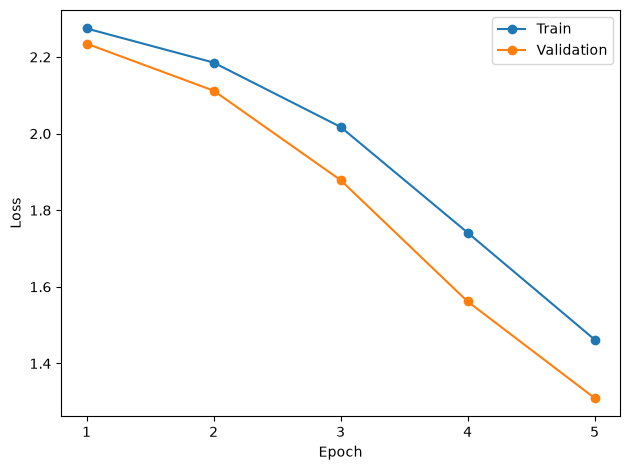

In [73]:
params1 = {
    "model_type": "MLP",
    "hidden_dims": [128, 64], 
    "channels": None, 
    "kernel_size": None,
    "activation": nn.ReLU, 
    "initialization": None,
    "optimizer": "SGD", 
    "learning_rate": 0.001, 
    "weight_decay": 0.0, 
    "momentum": 0.1,
    "dropout": 0.1,
    "epochs": 5,
    "batch_size": 64
}

model1, losses1, best_val_loss1, test_loss1 = run_experiment(params1, plotting = True)

